# Week 7 on a Mac: QLoRA fine-tuning with MLX

Days 1, 3, 4 and 5 of this week are Colab links, and day 2 needs an HF token. The Colab notebooks fine-tune
Llama 3.2 3B with **bitsandbytes** (4-bit base model), **PEFT** (LoRA adapters) and **TRL** (`SFTTrainer`) on an
NVIDIA GPU, and bitsandbytes only runs on CUDA. Apple's **MLX** does the same thing natively on Apple Silicon, so this
notebook covers all five days on the Mac with [local_finetune.py](local_finetune.py):

| course (Colab, CUDA) | here (M4 Pro, MLX) |
|--------|------|
| `meta-llama/Llama-3.2-3B` (gated, needs HF token) | `unsloth/Llama-3.2-3B`, an ungated copy of the same weights |
| `BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4")` | `mlx_lm.convert(..., quantize=True, q_bits=4)`: 4-bit affine, group size 64 |
| `LoraConfig(r, lora_alpha, target_modules, lora_dropout)` + `get_peft_model` | `linear_to_lora_layers` with `scale = lora_alpha / r` |
| `SFTTrainer` with prompt/completion data, loss on completion only | `mlx_lm.tuner.train` with a dataset that returns the prompt length as the loss-mask offset |
| `paged_adamw_32bit`, cosine schedule, 1% warmup | `optim.AdamW` + `linear_schedule` → `cosine_decay` |
| batch size 32 | micro-batches of 16 with 2 steps of gradient accumulation (32 at once needs ~22 GB) |
| `items_prompts_lite` pushed to the hub on day 2 | the same dataset, pulled from `ed-donner/items_prompts_lite` (public) |

The training itself runs from the command line (`uv run week7/local_finetune.py train lite`, about 2 hours),
and this notebook reads the adapters and logs it leaves in `week7/adapters/`.

In [1]:
import json
import time

import matplotlib.pyplot as plt
import mlx.core as mx
import mlx.nn as nn
from mlx_lm import load

import local_finetune as lf
from pricer.items import Item
from util import Tester

print("MLX device:", mx.default_device(), "| base model:", lf.BASE_HF)

MLX device: Device(gpu, 0) | base model: unsloth/Llama-3.2-3B


## Day 1 – QLoRA

Three ideas make it possible to fine-tune a 3B model on a laptop:

1. **Quantization** – store the frozen base weights in 4 bits instead of 16, cutting memory by ~3.5x.
2. **LoRA** – don't update the 3B weights at all. Next to chosen linear layers `W` (d×k), learn two thin matrices
   `A` (d×r) and `B` (r×k) and use `W + scale·A·B`. With r=32 that's a fraction of a percent of the parameters.
3. **Q + LoRA** – the base sits in 4 bits, the adapters train in full precision, and only the adapters get gradients
   and optimizer state.

### Quantization: the same model at 16, 8 and 4 bits

In [2]:
def footprint(model):
    return lf.parameter_bytes(model) / 1e9

model_16, tokenizer = load(str(lf.ensure_bf16_model()))  # bf16, as downloaded
print(f"bf16:  {footprint(model_16):.2f} GB")

nn.quantize(model_16, group_size=64, bits=8)
print(f"8-bit: {footprint(model_16):.2f} GB")

del model_16
mx.clear_cache()
model, tokenizer = lf.load_base()  # the 4-bit copy that every later step uses
print(f"4-bit: {footprint(model):.2f} GB")

bf16:  6.43 GB
8-bit: 3.41 GB


4-bit: 1.81 GB


bf16 → 8-bit → 4-bit: 6.43 → 3.41 → 1.81 GB. 4 bits for 3.2B weights would be 1.6 GB; the rest is the scale and
bias MLX keeps for every group of 64 weights (4.5 bits per weight overall). The architecture: 28 decoder layers, each
with attention (`q/k/v/o_proj`) and an MLP (`gate/up/down_proj`) – those linear layers are the LoRA targets.

In [3]:
print(model.model.layers[0])
print(f"{len(model.layers)} layers, hidden size {model.args.hidden_size}, vocabulary {model.args.vocab_size:,}")

TransformerBlock(
  (self_attn): Attention(
    (q_proj): QuantizedLinear(input_dims=3072, output_dims=3072, bias=False, group_size=64, bits=4, mode=affine)
    (k_proj): QuantizedLinear(input_dims=3072, output_dims=1024, bias=False, group_size=64, bits=4, mode=affine)
    (v_proj): QuantizedLinear(input_dims=3072, output_dims=1024, bias=False, group_size=64, bits=4, mode=affine)
    (o_proj): QuantizedLinear(input_dims=3072, output_dims=3072, bias=False, group_size=64, bits=4, mode=affine)
    (rope): Llama3RoPE()
  )
  (mlp): MLP(
    (gate_proj): QuantizedLinear(input_dims=3072, output_dims=8192, bias=False, group_size=64, bits=4, mode=affine)
    (down_proj): QuantizedLinear(input_dims=8192, output_dims=3072, bias=False, group_size=64, bits=4, mode=affine)
    (up_proj): QuantizedLinear(input_dims=3072, output_dims=8192, bias=False, group_size=64, bits=4, mode=affine)
  )
  (input_layernorm): RMSNorm(3072, eps=1e-05)
  (post_attention_layernorm): RMSNorm(3072, eps=1e-05)
)
28 layer

### LoRA: how many parameters do we actually train?

`r` is the rank of the adapters, `lora_alpha` scales their output, and `target_modules` picks which layers get them.
The course trains r=32 on the attention layers in lite mode and r=256 on attention + MLP for the full run.

In [4]:
experiments = {
    "lite: r=32, attention": lf.Config("a", lora_r=32, target_modules=lf.ATTENTION_LAYERS),
    "homework: r=64, attention + MLP": lf.Config("b", lora_r=64, target_modules=lf.ATTENTION_LAYERS + lf.MLP_LAYERS),
    "course full: r=256, attention + MLP": lf.Config("c", lora_r=256, target_modules=lf.ATTENTION_LAYERS + lf.MLP_LAYERS),
}
total = 3.21e9  # Llama 3.2 3B
for label, config in experiments.items():
    m, _ = lf.load_base()
    lf.add_lora(m, config)
    n = lf.trainable_parameters(m)
    print(f"{label:38} {n / 1e6:6.1f}M trainable  ({n / total:.2%} of the model, {n * 4 / 1e6:,.0f} MB in fp32)")
    del m
mx.clear_cache()

lite: r=32, attention                    18.4M trainable  (0.57% of the model, 73 MB in fp32)


homework: r=64, attention + MLP          97.3M trainable  (3.03% of the model, 389 MB in fp32)


course full: r=256, attention + MLP     389.0M trainable  (12.12% of the model, 1,556 MB in fp32)


## Day 2 – prompt data and the base model

### From items to prompts

The items are the week 6 lite dataset (20,000 train / 1,000 val / 1,000 test) with LLM-written summaries. Prompts
cut each summary at `CUTOFF` tokens so that a prompt plus its price fits in 128 tokens.

Loaded 20,000 training items, 1,000 validation items, 1,000 test items


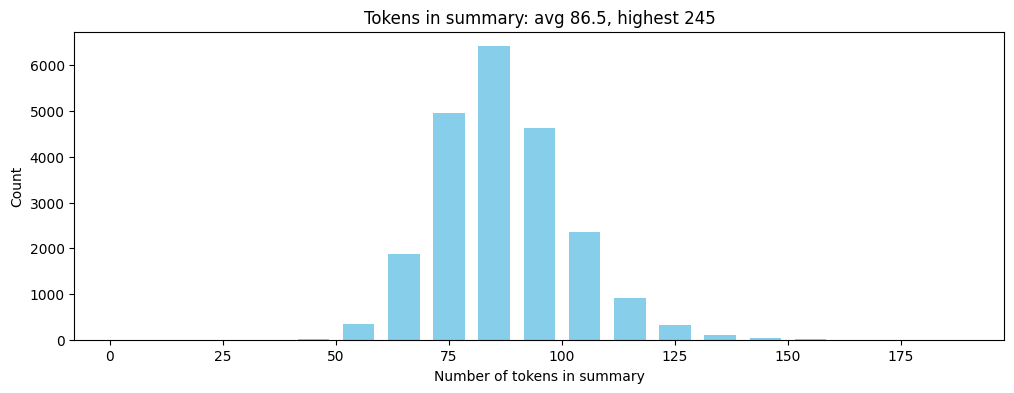

In [5]:
train, val, test = Item.from_hub("ed-donner/items_lite")
items = train + val + test
print(f"Loaded {len(train):,} training items, {len(val):,} validation items, {len(test):,} test items")

token_counts = [item.count_tokens(tokenizer) for item in items]
plt.figure(figsize=(12, 4))
plt.title(f"Tokens in summary: avg {sum(token_counts) / len(token_counts):,.1f}, highest {max(token_counts):,}")
plt.xlabel("Number of tokens in summary")
plt.ylabel("Count")
plt.hist(token_counts, rwidth=0.7, color="skyblue", bins=range(0, 200, 10))
plt.show()

In [6]:
CUTOFF = 110
cut = len([count for count in token_counts if count > CUTOFF])
print(f"With this CUTOFF, we will truncate {cut:,} items which is {cut / len(items):.1%}")

for item in train + val:
    item.make_prompts(tokenizer, CUTOFF, True)  # training prices rounded to the dollar: "64.00"
for item in test:
    item.make_prompts(tokenizer, CUTOFF, False)  # test keeps the real price

print("PROMPT:")
print(test[0].prompt)
print("COMPLETION:")
print(test[0].completion)

With this CUTOFF, we will truncate 1,255 items which is 5.7%


PROMPT:
What does this cost to the nearest dollar?

Title: Excess V2 Distortion/Modulation Pedal  
Category: Music Pedals  
Brand: Old Blood Noise  
Description: A versatile pedal offering distortion and three modulation modes—delay, chorus, and harmonized fifths—with full control over signal routing and expression.  
Details: Features include separate gain, tone, and volume controls; time, depth, and volume per modulation; order switching, soft‑touch bypass, and expression jack for dynamic control.

Price is $
COMPLETION:
219.0


The course pushes these to the hub as `items_prompts_lite`. Without an HF token we pull Ed's copy instead – and since
`unsloth/Llama-3.2-3B` has the same tokenizer as Meta's, every prompt we just built should match his exactly.

In [7]:
prompts = lf.load_prompts(lite=True)
ours = {"train": train, "val": val, "test": test}
for split, rows in prompts.items():
    same = sum(item.prompt == row["prompt"] and item.completion == row["completion"] for item, row in zip(ours[split], rows))
    print(f"{split:5}: {same:,} of {len(rows):,} prompt/completion pairs identical")

prompt_token_counts = [item.count_prompt_tokens(tokenizer) for item in items]
print(f"Longest prompt + completion: {max(prompt_token_counts)} tokens")

train: 20,000 of 20,000 prompt/completion pairs identical
val  : 1,000 of 1,000 prompt/completion pairs identical
test : 1,000 of 1,000 prompt/completion pairs identical


Longest prompt + completion: 126 tokens


### The base model, before any training

Greedy decoding after `Price is $`, scored on the first 200 test items with the course's `Tester` (average absolute
error). The course got **$110.72** for the 4-bit base model.

In [8]:
base_predict = lf.make_predictor(model, tokenizer)
print(repr(base_predict(prompts["test"][0])), "- truth:", prompts["test"][0]["completion"])

start = time.time()
base_tester = Tester(base_predict, prompts["test"], title="Base Llama 3.2 3B 4-bit")
base_tester.run()
print(f"{time.time() - start:.0f}s for 200 items")

39s for 200 items


On this run the base model did worse than in the course: **$190** against Ed's $110.72, with r² of −532%. That
says a handful of wild guesses dominate the average – a base model just continues text, and after `Price is $` it
sometimes writes a long or unrelated number. Either way it is the "before" picture: the model has no idea of the task.

## Days 3 and 4 – training

The hyperparameters follow the course's lite mode. One epoch over 20,000 items at batch size 32 is 625 optimizer
steps; each is two micro-batches of 16, because a batch of 32 doesn't fit next to everything else in 24 GB.

One change from the course's setup made training fit at all. mlx-lm's default loss projects *every* position onto
the 128k-token vocabulary and then masks the prompt away – for 16 prompts of 128 tokens that's 260 million logits
per step, for a loss that only looks at the 4 price tokens. `lf.completion_loss` runs the transformer as usual but
sends only the completion positions through the output layer. The loss is the same up to one detail – the default
also scores the padding token right after each end-of-text (an off-by-one in mlx-lm's mask) – at a fraction of the
memory:

In [9]:
from mlx_lm.tuner.datasets import CacheDataset
from mlx_lm.tuner.trainer import default_loss, iterate_batches

config = lf.CONFIGS["lite"]
for key, value in vars(config).items():
    print(f"{key:17} {value}")

sample = CacheDataset(lf.PromptCompletionDataset(prompts["train"][:16], tokenizer))
batch, lengths = next(iterate_batches(sample, 16, 128))
for name, loss_fn in [("default_loss", default_loss), ("completion_loss", lf.completion_loss)]:
    mx.clear_cache()
    mx.reset_peak_memory()
    loss, n_tokens = loss_fn(model, batch, lengths)
    mx.eval(loss)
    print(f"{name:16} loss {loss.item():.4f} over {n_tokens.item()} tokens, peak memory {mx.get_peak_memory() / 1e9:.1f} GB")

name              lite
lite              True
epochs            1
batch_size        32
micro_batch_size  16
max_seq_length    128
lora_r            32
lora_alpha        64
lora_dropout      0.1
target_modules    ['self_attn.q_proj', 'self_attn.k_proj', 'self_attn.v_proj', 'self_attn.o_proj']
learning_rate     0.0001
warmup_ratio      0.01
weight_decay      0.001
train_size        None
seed              42


default_loss     loss 7.1194 over 79 tokens, peak memory 3.1 GB


completion_loss  loss 3.5067 over 64 tokens, peak memory 2.6 GB


Training runs from a terminal (it takes about 2 hours and the notebook would sit blocked):

```bash
uv run week7/local_finetune.py train lite
```

Set `TRAIN_HERE = True` to run it from the notebook instead. Either way the adapters (~37 MB), their config and a
loss log land in `week7/adapters/lite/`.

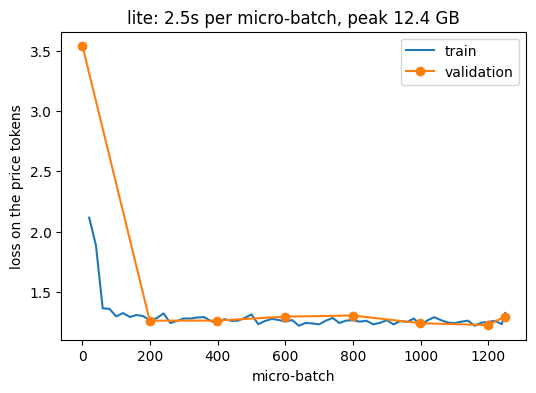

In [10]:
TRAIN_HERE = False
if TRAIN_HERE or not lf.is_trained("lite"):
    lf.run_training(lf.CONFIGS["lite"])


def plot_log(*names):
    fig, axes = plt.subplots(1, len(names), figsize=(6 * len(names), 4), squeeze=False)
    for ax, name in zip(axes[0], names):
        log = json.loads((lf.ADAPTERS_DIR / name / "log.json").read_text())
        ax.plot([r["iteration"] for r in log["train"]], [r["train_loss"] for r in log["train"]], label="train")
        ax.plot([r["iteration"] for r in log["val"]], [r["val_loss"] for r in log["val"]], "o-", label="validation")
        last = log["train"][-1]
        ax.set_title(f"{name}: {1 / last['iterations_per_second']:.1f}s per micro-batch, peak {last['peak_memory']:.1f} GB")
        ax.set_xlabel("micro-batch")
        ax.set_ylabel("loss on the price tokens")
        ax.legend()
    plt.show()


plot_log("lite")

The loss is only over the completion – the 3 to 4 tokens of the price (`64`, `.`, `00`, end of text) – so it drops
quickly once the model learns the format, and the rest of the run is about getting the dollar token right.

## Day 5 – evaluation

Load the 4-bit base again, put the trained adapters on top, and run the same 200 test items.

In [11]:
del model
mx.clear_cache()
ft_model, tokenizer = lf.load_finetuned("lite")
ft_tester = Tester(lf.make_predictor(ft_model, tokenizer), prompts["test"], title="Fine-tuned lite (local)")
ft_tester.run()

### An experiment: read the probabilities instead of the top token

Llama 3's tokenizer has a single token for every number from 0 to 999, and every price here is below $1,000, so the
whole dollar amount is *one* token. Instead of taking the most likely token, blend the five most likely prices by
their probability. When the model hesitates between $40 and $60, answering $50 costs less than picking the wrong one.

In [12]:
weighted_tester = Tester(lf.make_weighted_predictor(ft_model, tokenizer), prompts["test"], title="Fine-tuned lite, top-5 weighted")
weighted_tester.run()

It didn't help here: **$57.97** against **$56.25** for plain greedy decoding. Blending pulls every answer towards the
middle of the model's distribution, which pays off when the model is unsure between neighbours, but costs on items
where the top guess was right and the runners-up are far off. Greedy stays the predictor of choice.

### Homework: beat the lite score

The course invites you to experiment with the hyperparameters. The run `lite-mlp` keeps the same data, one epoch and
learning rate, but gives the adapters 5x the capacity: r=64 on the MLP layers as well as attention, as in the
course's full run (`uv run week7/local_finetune.py train lite-mlp`, about 2 hours).

Two false starts on the way: with the learning rate doubled to 2e-4 the loss jumped to 8.5 by step 40, and with
micro-batches of 16 the peak hit 19 GB and the run died at step 240. Micro-batches of 8 (4 accumulation steps, so
still 32 per update) peak at 11.8 GB.

In [13]:
mlp_tester = None
if lf.is_trained("lite-mlp"):
    plot_log("lite", "lite-mlp")
    mlp_model, tokenizer = lf.load_finetuned("lite-mlp")
    mlp_tester = Tester(lf.make_predictor(mlp_model, tokenizer), prompts["test"], title="Fine-tuned lite-mlp")
    mlp_tester.run()
    del mlp_model
else:
    print("lite-mlp isn't trained yet: uv run week7/local_finetune.py train lite-mlp")

**Result: $59.18 – the homework did not beat lite ($56.25).** Five times the trainable parameters (97M vs 18M), the same
data and nearly the same training time (115 vs 108 minutes) gave a slightly *worse* error, with a lower r² (53% vs 59%).
The $3 gap is well inside the ±$11 confidence band of a 200-item test, so the fair reading is a tie, not a regression –
but either way extra capacity bought nothing. With 20,000 examples seen once, the adapters on attention alone already
fit what the data can teach; the course's full run gets to $39.85 by training on far more data, not just a bigger r.
The next experiment worth the GPU time is more data or a second epoch, not more parameters.

### Where this puts us

The course's results chart from `results.ipynb`, with this week's local runs added (all scored on the same 200
test items with the same `Tester`).

In [14]:
import plotly.graph_objects as go

def average(tester):
    return sum(tester.errors) / len(tester.errors)

results = [
    ("Constant", "gray", 106.18),
    ("Linear Regression", "gray", 101.56),
    ("NLP + LR", "gray", 76.81),
    ("Random Forest", "gray", 72.28),
    ("XGBoost", "gray", 68.23),
    ("Human (Ed)", "black", 87.62),
    ("Neural Network", "orange", 63.97),
    ("GPT 4.1 Nano", "slateblue", 62.51),
    ("Claude 4.5 Sonnet", "slateblue", 47.10),
    ("GPT 5.1", "slateblue", 44.74),
    ("Deep Neural Network", "orange", 46.49),
    ("Base Llama 3.2 4 bit", "darkred", 110.72),
    ("Fine-tuned Lite", "red", 65.40),
    ("Fine-tuned Full", "red", 39.85),
    ("Mac: base 4-bit", "darkgreen", average(base_tester)),
    ("Mac: lite", "green", average(ft_tester)),
    ("Mac: lite, weighted", "green", average(weighted_tester)),
  ]
if mlp_tester:
    results.append(("Mac: lite-mlp", "green", average(mlp_tester)))
labels, colors, values = zip(*results)
fig = go.Figure(go.Bar(x=labels, y=values, marker_color=colors, text=[f"${v:.0f}" for v in values], textposition="outside"))
fig.update_layout(title="Prediction error from each model (lower is better)", yaxis=dict(title="Average error ($)"),
                  xaxis=dict(tickangle=-45), width=1000, height=600)
fig.show()

**Takeaway.** QLoRA on a laptop works: one epoch over 20,000 items took 108 minutes on the M4 Pro and brought the
3B model from $190 to **$56.25** – better than the course's lite run ($65.40), XGBoost ($68.23) and GPT 4.1 Nano
($62.51), though still short of the full run ($39.85), which trains on far more data for more epochs. Neither
blending the top-5 prices ($57.97) nor 5x larger adapters ($59.18) improved on the plain lite run.

# Week 7 exercise – the Spanish tutor's article checker

Every flashcard the tutor writes must carry the noun's definite article (*la carpeta*, *el éxito*). That's where
small models slip: *el problema*, *el día*, *el agua* (feminine, but *el* before a stressed *a-*), *la mano*,
*la foto*, *la carne*. So the exercise points this week's recipe at the tutor: a 3B model fine-tuned with QLoRA to
say *el* or *la*, and compared with what the tutor uses today. [article_finetune.py](article_finetune.py):

* **Gold labels** from [AnCora](https://github.com/UniversalDependencies/UD_Spanish-AnCora), 500k words of
  hand-annotated Spanish (CC BY 4.0). Each *el*/*la* directly in front of a singular noun is a vote; nouns seen at
  least twice with ≥90% agreement get a label, the rest (*el/la capital*, *el/la final*) are set aside as ambiguous.
* **Split by noun**, 80/10/10, so no test noun is seen in training.
* **Baselines**: the classroom rule (-a → *la*), the textbook rule (+ -ión, -dad, -umbre → *la*; -ema, -aje, -or
  → *el*), the base model, and the tutor's Ollama models.
* **Scoring** on all test nouns and on the *irregular* ones – those the textbook rule gets wrong.

In [15]:
import article_finetune as af

articles = af.load_data()
print({split: len(rows) for split, rows in articles.items()})
print("Some ambiguous nouns:", ", ".join(f"{n} {c}" for n, c in list(articles["ambiguous"].items())[:8]))
print("Training example:", af.to_datapoint(articles["train"][0]))

{'train': 2110, 'val': 255, 'test': 275, 'ambiguous': 40}
Some ambiguous nouns: artista {'la': 5, 'el': 5}, base {'la': 19, 'el': 9}, batería {'la': 4, 'el': 1}, canadiense {'la': 3, 'el': 3}, cantante {'el': 2, 'la': 5}, capital {'la': 72, 'el': 14}, central {'la': 7, 'el': 8}, ciclista {'el': 5, 'la': 1}
Training example: {'prompt': 'Which definite article does this Spanish noun take?\n\nNoun: abeto\n\nArticle:', 'completion': ' el'}


Training: 2 epochs over 2,110 nouns at batch size 16 (264 steps), r=16 on the attention layers – a few minutes.

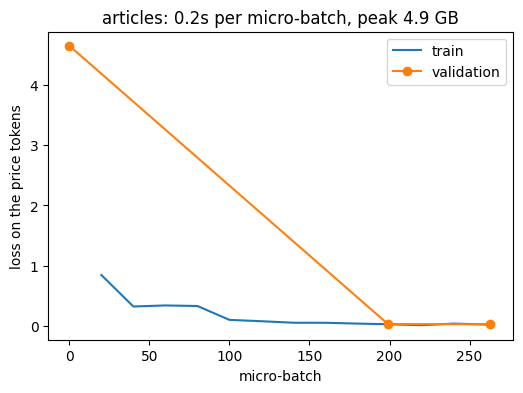

In [16]:
if not lf.is_trained("articles"):
    af.train()
plot_log("articles")

In [17]:
import pandas as pd

del ft_model
mx.clear_cache()
base_model, tokenizer = lf.load_base()
article_model, _ = lf.load_finetuned("articles")

contenders = {
    "classroom rule (-a → la)": af.classroom_rule,
    "textbook rule": af.better_rule,
    "Llama 3.2 3B base (4-bit)": af.make_llama_classifier(base_model, tokenizer),
    "Ollama llama3.2 (tutor default)": af.make_ollama_classifier("llama3.2"),
    "Ollama qwen2.5:14b": af.make_ollama_classifier("qwen2.5:14b"),
    "Llama 3.2 3B + LoRA (fine-tuned)": af.make_llama_classifier(article_model, tokenizer),
}
scores = {}
for name, predict in contenders.items():
    start = time.time()
    scores[name] = af.score(predict, articles["test"]) | {"seconds": time.time() - start}

table = pd.DataFrame(scores).T
table["accuracy"] = table["accuracy"].map("{:.1%}".format)
table["hard_accuracy"] = table["hard_accuracy"].map("{:.1%}".format)
table["seconds"] = table["seconds"].map("{:.0f}".format)
table["mistakes"] = table["mistakes"].map(lambda m: ", ".join(m[:8]) + (" ..." if len(m) > 8 else ""))
pd.set_option("display.max_colwidth", 140)
table[["accuracy", "hard_accuracy", "seconds", "mistakes"]]

,accuracy,hard_accuracy,seconds,mistakes
classroom rule (-a → la),73.5%,0.0%,0,"el actitud, el adaptación, el aniquilación, el beatificación, el capacitación, el carne, el catástrofe, la ceramista ..."
textbook rule,94.2%,0.0%,0,"el carne, el catástrofe, la ceramista, la cisma, el clase, la cura, el cúspide, el institució ..."
Llama 3.2 3B base (4-bit),94.9%,62.5%,12,"el carne, el clonación, la cura, el cúspide, el emoción, el esquina, el exención, el ilusión ..."
Ollama llama3.2 (tutor default),69.8%,43.8%,67,"el actitud, el alianza, el altura, el avería, el basura, el carne, el carrera, el catástrofe ..."
Ollama qwen2.5:14b,98.9%,93.8%,164,"el carne, el plata, la rosario"
Llama 3.2 3B + LoRA (fine-tuned),98.9%,81.2%,22,"la cura, el peste, el tele"


What the table says (275 test nouns, none seen in training; "hard" = the 16 that break the textbook rule):

* The tutor's default model, **llama3.2, gets 70%** – it writes *el actitud*, *el carne*, *el clase*. Nearly every
  third noun card would teach a mistake. Even the classroom rule does better.
* The textbook rule alone reaches 94%. The base 3B model, asked to choose between the ` el` and ` la` tokens, is
  already at 95% – it has read a lot of Spanish – but stumbles on *-ión* words (*el emoción*, *el ilusión*).
* After 6 minutes of QLoRA it reaches **98.9%, the same as qwen2.5:14b**, in about 20 seconds instead of 164 and with a
  model a quarter of the size. On the irregular nouns qwen is still ahead (94% vs 81%).

And the hook into the tutor: check the decks it already wrote. Every card of the form *el/la + noun* is
compared with the fine-tuned model; disagreements are worth a second look before the deck is studied.

In [18]:
predict_article = af.make_llama_classifier(article_model, tokenizer)
for noun in ["agua", "problema", "mano", "foto", "día", "carne", "paz", "mapa", "águila", "tribu"]:
    print(f"{predict_article(noun)} {noun}", end="   ")
print()

deck = lf.WEEK7.parent / "week2" / "decks" / "False_Friends__Falsos_Amigos_.csv"
if deck.exists():
    print("\n".join(af.check_deck(deck, predict_article)) or f"{deck.name}: every article matches the model")

la agua   el problema   la mano   la foto   

el día   la carne   la paz   el mapa   

la águila   la tribu   


False_Friends__Falsos_Amigos_.csv: every article matches the model


Not solved: **la agua** and **la águila** are wrong. Feminine nouns that start with a stressed *a-* take *el* in the
singular (*el agua*, *el águila*, *el hambre*), and AnCora has only a handful of them – *agua* itself landed in the
validation split. The model learnt gender, not this phonetic rule. The next step would be to add these nouns to
training (or put that one rule in front of the model), since they are exactly what a learner gets wrong.